In [1]:
DEPLOYMENT_LINK = "https://seoul-bike-fa24-bse-113.streamlit.app/"


In [2]:
import sys, subprocess, importlib.util
required = {'sklearn':'scikit-learn==1.9.1', 'pandas':'pandas==3.0.1',
            'numpy':'numpy==2.3.5', 'matplotlib':'matplotlib==3.10.8',
            'joblib':'joblib==1.6.0'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import os, json, time, hashlib, platform, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from IPython.display import display
from IPython.display import HTML

class FitProgress:
    def __init__(self, total, **kwargs): self.total, self.done = total, 0
    def __enter__(self):
        self.start = time.perf_counter()
        self.handle = display(HTML('<progress value="0" max="50"></progress>'), display_id=True)
        return self
    def set_postfix(self, **kwargs): self.label = str(kwargs)
    def update(self, count=1):
        self.done += count
        elapsed = time.perf_counter()-self.start
        eta = elapsed*(self.total-self.done)/self.done
        self.handle.update(HTML(f'<progress value="{self.done}" max="{self.total}"></progress> {self.done}/{self.total} fits | elapsed {elapsed:.1f}s | estimated remaining {eta:.1f}s | {self.label}'))
    def __exit__(self, *args): return False
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
OUT = Path('results'); OUT.mkdir(exist_ok=True)
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)
print('All libraries imported.')


Python: 3.12.14 | scikit-learn: 1.9.1
All libraries imported.


In [3]:
DATA_FILE = Path('SeoulBikeData.csv')
if not DATA_FILE.exists():
    try:
        from google.colab import files
        print('Upload SeoulBikeData.csv now.')
        files.upload()
    except ImportError:
        raise FileNotFoundError('Place SeoulBikeData.csv beside this notebook, then rerun.')
if not DATA_FILE.exists():
    raise FileNotFoundError('Expected the exact filename SeoulBikeData.csv.')
raw = pd.read_csv(DATA_FILE, encoding='cp1252')
print('Full dataset shape:', raw.shape)
display(raw.head())
assert raw.shape == (8760, 14), 'Expected the full supplied UCI dataset.'
dataset_sha256 = hashlib.sha256(DATA_FILE.read_bytes()).hexdigest()


Full dataset shape: (8760, 14)


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [4]:
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum()}))
print('Duplicate rows:', raw.duplicated().sum())
print('Date range:', pd.to_datetime(raw['Date'], format='%d/%m/%Y').min(), 'to', pd.to_datetime(raw['Date'], format='%d/%m/%Y').max())
display(raw['Rented Bike Count'].describe())
display(raw.groupby('Functioning Day')['Rented Bike Count'].agg(['count','min','max','mean']))
assert raw.duplicated().sum() == 0
assert raw['Rented Bike Count'].notna().all() and (raw['Rented Bike Count'] >= 0).all()
print('All 8,760 rows retained, including zero-demand hours.')


,dtype,missing
Date,str,0
Rented Bike Count,int64,0
Hour,int64,0
Temperature(°C),float64,0
Humidity(%),int64,0
Wind speed (m/s),float64,0
Visibility (10m),int64,0
Dew point temperature(°C),float64,0
Solar Radiation (MJ/m2),float64,0
Rainfall(mm),float64,0


Duplicate rows: 0
Date range: 2017-12-01 00:00:00 to 2018-11-30 00:00:00


count    8760.000000
mean      704.602055
std       644.997468
min         0.000000
25%       191.000000
50%       504.500000
75%      1065.250000
max      3556.000000
Name: Rented Bike Count, dtype: float64

,count,min,max,mean
Functioning Day,,,,
No,295,0,0,0.000000
Yes,8465,2,3556,729.156999


All 8,760 rows retained, including zero-demand hours.


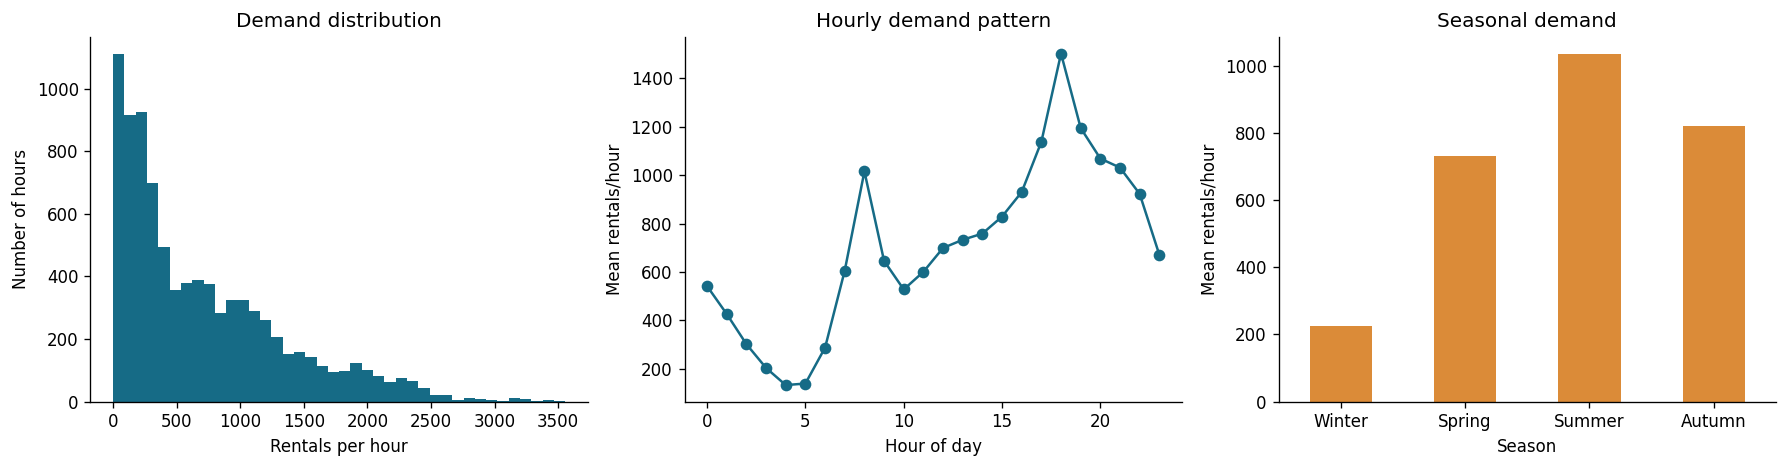

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(raw['Rented Bike Count'], bins=40, color='#166b86')
axes[0].set(xlabel='Rentals per hour', ylabel='Number of hours', title='Demand distribution')
raw.groupby('Hour')['Rented Bike Count'].mean().plot(ax=axes[1], marker='o', color='#166b86')
axes[1].set(xlabel='Hour of day', ylabel='Mean rentals/hour', title='Hourly demand pattern')
raw.groupby('Seasons')['Rented Bike Count'].mean().reindex(['Winter','Spring','Summer','Autumn']).plot.bar(ax=axes[2], color='#db8b38', rot=0)
axes[2].set(xlabel='Season', ylabel='Mean rentals/hour', title='Seasonal demand')
fig.tight_layout(); fig.savefig(OUT / 'eda_patterns.png', dpi=180, bbox_inches='tight'); plt.show()


In [6]:
from pathlib import Path
import numpy as np
import pandas as pd

TARGET = "Rented Bike Count"
RENAME = {
    "Temperature(°C)": "Temperature", "Humidity(%)": "Humidity",
    "Wind speed (m/s)": "Wind speed", "Visibility (10m)": "Visibility",
    "Dew point temperature(°C)": "Dew point temperature",
    "Solar Radiation (MJ/m2)": "Solar Radiation", "Rainfall(mm)": "Rainfall",
    "Snowfall (cm)": "Snowfall"
}

def prepare_features(raw):

    frame = raw.rename(columns=RENAME).copy()
    dates = pd.to_datetime(frame.pop("Date"), format="%d/%m/%Y", errors="raise")
    frame = frame.drop(columns=[TARGET], errors="ignore")
    frame["Month"] = dates.dt.month
    frame["Day of week"] = dates.dt.dayofweek
    frame["Day of year"] = dates.dt.dayofyear
    frame["Weekend"] = (dates.dt.dayofweek >= 5).astype(int)
    frame["Hour sin"] = np.sin(2 * np.pi * frame["Hour"] / 24)
    frame["Hour cos"] = np.cos(2 * np.pi * frame["Hour"] / 24)
    frame["Month sin"] = np.sin(2 * np.pi * (frame["Month"] - 1) / 12)
    frame["Month cos"] = np.cos(2 * np.pi * (frame["Month"] - 1) / 12)
    return frame

X = prepare_features(raw)
y = pd.to_numeric(raw[TARGET], errors='raise').astype(float)
assert TARGET not in X.columns and len(X) == len(raw)
print('Features:', X.shape, '| Target:', y.shape)
display(X.head())


Features: (8760, 20) | Target: (8760,)


,Hour,Temperature,Humidity,Wind speed,Visibility,Dew point temperature,Solar Radiation,Rainfall,Snowfall,Seasons,Holiday,Functioning Day,Month,Day of week,Day of year,Weekend,Hour sin,Hour cos,Month sin,Month cos
0,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,4,335,0,0.000000,1.000000,-0.5,0.866025
1,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,4,335,0,0.258819,0.965926,-0.5,0.866025
2,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,12,4,335,0,0.500000,0.866025,-0.5,0.866025
3,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,4,335,0,0.707107,0.707107,-0.5,0.866025
4,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,4,335,0,0.866025,0.500000,-0.5,0.866025


In [7]:
numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(exclude='number').columns.tolist()
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_features),
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                              ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical_features)
])
print('Numeric:', numeric_features)
print('Categorical:', categorical_features)


Numeric: ['Hour', 'Temperature', 'Humidity', 'Wind speed', 'Visibility', 'Dew point temperature', 'Solar Radiation', 'Rainfall', 'Snowfall', 'Month', 'Day of week', 'Day of year', 'Weekend', 'Hour sin', 'Hour cos', 'Month sin', 'Month cos']
Categorical: ['Seasons', 'Holiday', 'Functioning Day']


In [8]:
models = {
    'Ridge Regression': Ridge(alpha=10.0),
    'Lasso Regression': Lasso(alpha=0.1, max_iter=20000, tol=1e-4),
    'Elastic Net': ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000, tol=1e-4),
    'Support Vector Regression': SVR(kernel='rbf', C=100, epsilon=10, cache_size=512),
    'Extra Trees Regressor': ExtraTreesRegressor(n_estimators=120, min_samples_leaf=2, max_features=1.0, random_state=42, n_jobs=2)
}
for name, estimator in models.items():
    print(name, ':', estimator)


Ridge Regression : Ridge(alpha=10.0)
Lasso Regression : Lasso(alpha=0.1, max_iter=20000)
Elastic Net : ElasticNet(alpha=0.1, max_iter=20000)
Support Vector Regression : SVR(C=100, cache_size=512, epsilon=10)
Extra Trees Regressor : ExtraTreesRegressor(min_samples_leaf=2, n_estimators=120, n_jobs=2,
                    random_state=42)


In [9]:
folds = list(KFold(n_splits=10, shuffle=True, random_state=42).split(X))
fold_records = []
oof_predictions = {}
with FitProgress(total=len(models) * len(folds)) as progress:
    for name, estimator in models.items():
        oof = np.full(len(y), np.nan)
        for fold, (train_idx, valid_idx) in enumerate(folds, start=1):
            started = time.perf_counter()
            pipeline = Pipeline([('preprocessor', clone(preprocessor)), ('model', clone(estimator))])
            pipeline.fit(X.iloc[train_idx], y.iloc[train_idx])
            pred = np.maximum(0, pipeline.predict(X.iloc[valid_idx]))
            oof[valid_idx] = pred
            fold_records.append({'Algorithm':name, 'Fold':fold, 'Train rows':len(train_idx), 'Validation rows':len(valid_idx),
                'RMSE':float(np.sqrt(mean_squared_error(y.iloc[valid_idx], pred))),
                'MAE':float(mean_absolute_error(y.iloc[valid_idx], pred)),
                'R2':float(r2_score(y.iloc[valid_idx], pred)), 'Seconds':time.perf_counter()-started})
            progress.set_postfix(model=name, fold=fold)
            progress.update(1)
        assert np.isfinite(oof).all()
        oof_predictions[name] = oof
fold_df = pd.DataFrame(fold_records)
results_df = fold_df.groupby('Algorithm', sort=False).agg(
    Mean_RMSE=('RMSE','mean'), Std_RMSE=('RMSE','std'), Mean_MAE=('MAE','mean'),
    Mean_R2=('R2','mean'), Total_seconds=('Seconds','sum')).reset_index().sort_values('Mean_RMSE').reset_index(drop=True)
results_df.columns = ['Algorithm','Mean RMSE','Std RMSE','Mean MAE','Mean R2','Total seconds']
fold_df.to_csv(OUT / 'fold_results.csv', index=False)
results_df.to_csv(OUT / 'model_comparison.csv', index=False)
display(fold_df.round(3))
display(results_df.round(3))
assert len(fold_df) == 50 and (fold_df['Validation rows'] == 876).all()
for name, predictions in oof_predictions.items():
    print(f'{name}: pooled out-of-fold RMSE = {np.sqrt(mean_squared_error(y, predictions)):.2f} bikes/hour')


,Algorithm,Fold,Train rows,Validation rows,RMSE,MAE,R2,Seconds
0,Ridge Regression,1,7884,876,405.410,291.538,0.605,0.159
1,Ridge Regression,2,7884,876,423.522,311.468,0.569,0.069
2,Ridge Regression,3,7884,876,395.534,289.103,0.605,0.075
3,Ridge Regression,4,7884,876,437.208,315.656,0.556,0.079
4,Ridge Regression,5,7884,876,378.894,283.122,0.628,0.098
5,Ridge Regression,6,7884,876,407.869,294.418,0.630,0.081
6,Ridge Regression,7,7884,876,390.848,284.889,0.645,0.069
7,Ridge Regression,8,7884,876,397.526,291.821,0.600,0.070
8,Ridge Regression,9,7884,876,418.678,301.005,0.590,0.065
9,Ridge Regression,10,7884,876,392.780,288.650,0.621,0.062


,Algorithm,Mean RMSE,Std RMSE,Mean MAE,Mean R2,Total seconds
0,Extra Trees Regressor,151.639,10.842,82.399,0.944,21.520
1,Support Vector Regression,269.753,20.739,154.989,0.824,36.196
2,Lasso Regression,404.505,17.560,294.861,0.606,1.562
3,Ridge Regression,404.827,17.487,295.167,0.605,0.825
4,Elastic Net,421.567,16.375,306.847,0.572,0.770


Ridge Regression: pooled out-of-fold RMSE = 405.17 bikes/hour
Lasso Regression: pooled out-of-fold RMSE = 404.85 bikes/hour
Elastic Net: pooled out-of-fold RMSE = 421.85 bikes/hour
Support Vector Regression: pooled out-of-fold RMSE = 270.47 bikes/hour
Extra Trees Regressor: pooled out-of-fold RMSE = 151.99 bikes/hour


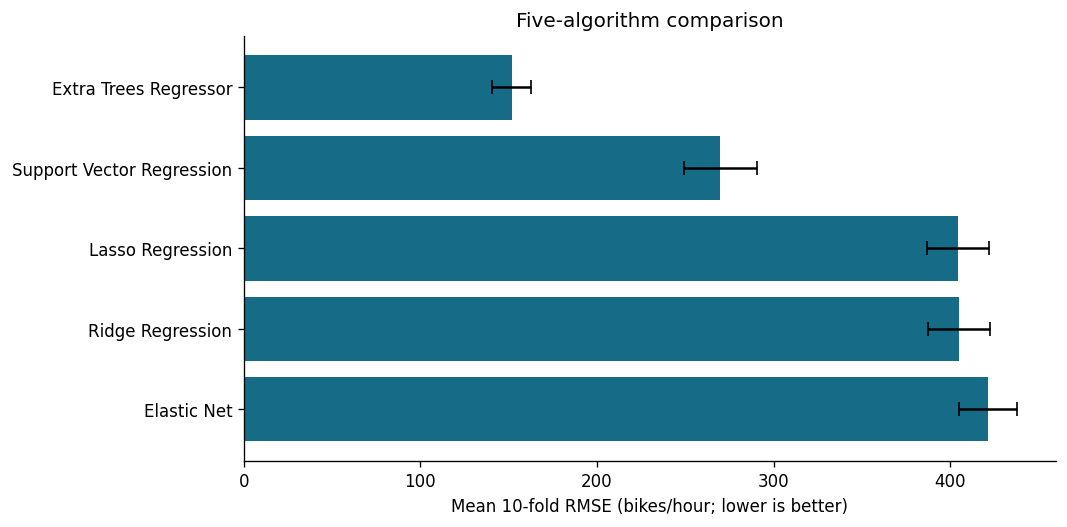

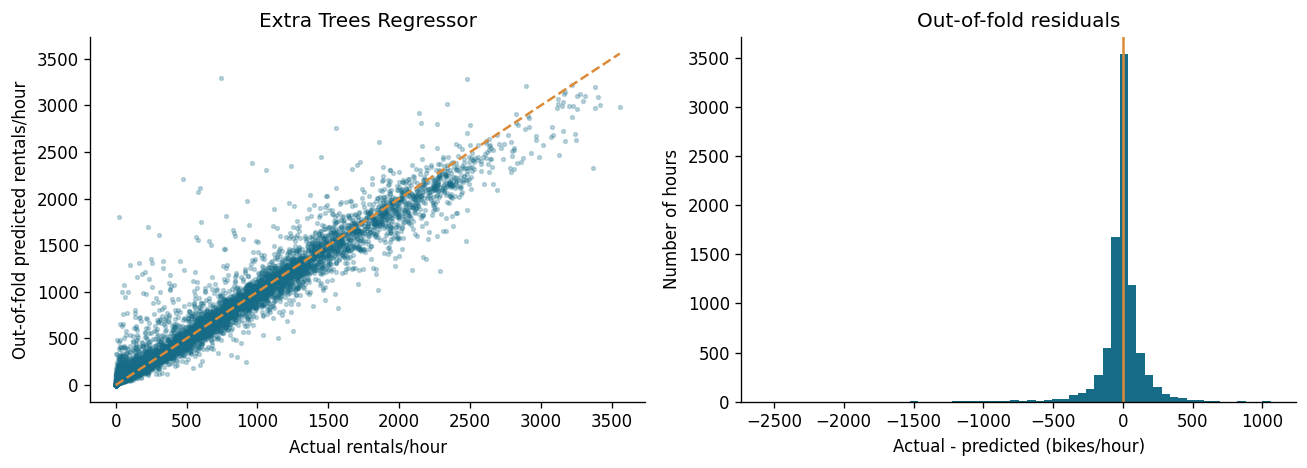

Selected algorithm: Extra Trees Regressor; mean CV RMSE = 151.64 bikes/hour.


In [10]:
best_algorithm = results_df.iloc[0]['Algorithm']
best_rmse = float(results_df.iloc[0]['Mean RMSE'])
fig, ax = plt.subplots(figsize=(9,4.5))
ordered = results_df.iloc[::-1]
ax.barh(ordered['Algorithm'], ordered['Mean RMSE'], xerr=ordered['Std RMSE'], color='#166b86', capsize=4)
ax.set(xlabel='Mean 10-fold RMSE (bikes/hour; lower is better)', title='Five-algorithm comparison')
fig.tight_layout(); fig.savefig(OUT / 'rmse_comparison.png', dpi=180, bbox_inches='tight'); plt.show()
best_oof = oof_predictions[best_algorithm]
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(y,best_oof,s=5,alpha=0.25,color='#166b86'); axes[0].plot([0,y.max()],[0,y.max()],'--',color='#db8b38')
axes[0].set(xlabel='Actual rentals/hour',ylabel='Out-of-fold predicted rentals/hour',title=best_algorithm)
axes[1].hist(y-best_oof,bins=60,color='#166b86'); axes[1].axvline(0,color='#db8b38')
axes[1].set(xlabel='Actual - predicted (bikes/hour)',ylabel='Number of hours',title='Out-of-fold residuals')
fig.tight_layout(); fig.savefig(OUT / 'oof_diagnostics.png',dpi=180,bbox_inches='tight'); plt.show()
pd.DataFrame({'Row':np.arange(len(raw)), 'Date':raw['Date'], 'Hour':raw['Hour'], 'Actual':y,
              'OOF prediction':best_oof, 'OOF residual':y-best_oof}).to_csv(OUT / 'oof_predictions.csv',index=False)
print(f'Selected algorithm: {best_algorithm}; mean CV RMSE = {best_rmse:.2f} bikes/hour.')


In [11]:
timestamps = pd.to_datetime(raw['Date'], format='%d/%m/%Y') + pd.to_timedelta(raw['Hour'],unit='h')
order = np.argsort(timestamps.to_numpy())
cut = int(len(order)*0.8)
early, late = order[:cut], order[cut:]
temporal_pipeline = Pipeline([('preprocessor',clone(preprocessor)),('model',clone(models[best_algorithm]))])
temporal_pipeline.fit(X.iloc[early],y.iloc[early])
temporal_pred = np.maximum(0,temporal_pipeline.predict(X.iloc[late]))
temporal_result = {'train_rows':len(early),'test_rows':len(late),
    'train_end':str(timestamps.iloc[early].max()),'test_start':str(timestamps.iloc[late].min()),
    'RMSE':float(np.sqrt(mean_squared_error(y.iloc[late],temporal_pred))),
    'MAE':float(mean_absolute_error(y.iloc[late],temporal_pred)),
    'R2':float(r2_score(y.iloc[late],temporal_pred))}
print(json.dumps(temporal_result,indent=2))
(OUT / 'chronological_holdout.json').write_text(json.dumps(temporal_result,indent=2),encoding='utf-8')


{
  "train_rows": 7008,
  "test_rows": 1752,
  "train_end": "2018-09-18 23:00:00",
  "test_start": "2018-09-19 00:00:00",
  "RMSE": 249.65422449388947,
  "MAE": 171.13533669004133,
  "R2": 0.834313886546727
}


208

In [12]:
final_pipeline = Pipeline([('preprocessor',clone(preprocessor)),('model',clone(models[best_algorithm]))])
final_pipeline.fit(X,y)
joblib.dump(final_pipeline, 'seoul_bike_model.pkl', compress=3)

import inspect
feature_source = inspect.getsource(prepare_features)
Path('features.py').write_text('import numpy as np\nimport pandas as pd\nTARGET = '+repr(TARGET)+'\nRENAME = '+repr(RENAME)+'\n\n'+feature_source,encoding='utf-8')
metadata = {'student':'Shifa Zeeshan','roll_number':'FA24-BSE-113','section':'B',
    'dataset_rows':len(raw),'dataset_columns':len(raw.columns),'dataset_sha256':dataset_sha256,
    'best_algorithm':best_algorithm,'best_mean_rmse':best_rmse,'target':TARGET,
    'features':X.columns.tolist(),'python':platform.python_version(),'sklearn':sklearn.__version__,
    'numpy':np.__version__,'pandas':pd.__version__,'joblib':joblib.__version__,
    'cv':'10-fold shuffled KFold, random_state=42','prediction_postprocessing':'clip lower bound at zero',
    'model_parameters':{name:model.get_params() for name,model in models.items()},
    'chronological_holdout':temporal_result}
Path('model_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('Saved seoul_bike_model.pkl, features.py, and model_metadata.json')
loaded_pipeline = joblib.load('seoul_bike_model.pkl')
assert np.allclose(final_pipeline.predict(X.iloc[:12]),loaded_pipeline.predict(X.iloc[:12]))
print('Reloaded model predictions match.')
Path("pyproject.toml").write_text('[tool.poetry]\nname = "seoul-bike-demand"\nversion = "1.0.0"\ndescription = ""\nauthors = ["Shifa Zeeshan"]\npackage-mode = false\n\n[tool.poetry.dependencies]\npython = ">=3.12,<3.14"\nstreamlit = "1.64.0"\npandas = "{pandas}"\nnumpy = "{numpy}"\nscikit-learn = "{sklearn}"\njoblib = "{joblib}"\n'.format(pandas=pd.__version__, numpy=np.__version__, sklearn=sklearn.__version__, joblib=joblib.__version__), encoding="utf-8")


Saved seoul_bike_model.pkl, features.py, and model_metadata.json


Reloaded model predictions match.


271

In [13]:
example_idx = 18
display(raw.iloc[[example_idx]])
print(f'Actual hourly rentals: {y.iloc[example_idx]:.0f}')
print(f'Out-of-fold prediction: {best_oof[example_idx]:.1f}')
print(f'Absolute held-out error: {abs(y.iloc[example_idx]-best_oof[example_idx]):.1f}')


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
18,01/12/2017,862,18,0.6,66,1.4,2000,-5.0,0.0,0.0,0.0,Winter,No Holiday,Yes


Actual hourly rentals: 862
Out-of-fold prediction: 647.5
Absolute held-out error: 214.5


In [14]:
winner = results_df.iloc[0]
display(results_df.round(3))
print(best_algorithm, best_rmse)
print(temporal_result)


,Algorithm,Mean RMSE,Std RMSE,Mean MAE,Mean R2,Total seconds
0,Extra Trees Regressor,151.639,10.842,82.399,0.944,21.520
1,Support Vector Regression,269.753,20.739,154.989,0.824,36.196
2,Lasso Regression,404.505,17.560,294.861,0.606,1.562
3,Ridge Regression,404.827,17.487,295.167,0.605,0.825
4,Elastic Net,421.567,16.375,306.847,0.572,0.770


Extra Trees Regressor 151.63855797485712
{'train_rows': 7008, 'test_rows': 1752, 'train_end': '2018-09-18 23:00:00', 'test_start': '2018-09-19 00:00:00', 'RMSE': 249.65422449388947, 'MAE': 171.13533669004133, 'R2': 0.834313886546727}


In [15]:
with zipfile.ZipFile('seoul_bike_training_outputs.zip','w',compression=zipfile.ZIP_DEFLATED) as archive:
    for filename in ['seoul_bike_model.pkl','features.py','model_metadata.json','pyproject.toml']:
        archive.write(filename)
    for filename in sorted(OUT.glob('*')):
        if filename.is_file(): archive.write(filename,filename.as_posix())
print('Created seoul_bike_training_outputs.zip. Download it from the Colab Files panel.')


Created seoul_bike_training_outputs.zip. Download it from the Colab Files panel.
